EDA Assignment: Does More Health Spending = Longer Life?
**Name:** *Student*  |  **Date:** *Today*  |  ⏱️ *Target time: ~1 hour*

---
### 🤔 The big question
Every country spends money on healthcare — some spend *a lot* more than others. It seems obvious that **spending more should mean people live longer**... right?

**Your job:** use EDA to find out if that's actually true. This is an **open-ended** assignment — there's no single "correct" cell to fill in. You explore the data, follow what's interesting, and back up your answer with charts.

> 🎯 **Before you touch the data, write your gut guess here:**
> *Do you think the country that spends the MOST on healthcare also lives the longest? (yes / no / not sure):* **no**

**The dataset:** health spending per person vs life expectancy, for 6 wealthy countries, 1970–2020 (real OECD-style data, built into seaborn — loads offline).

### 📤 What to hand in
Answer every ✍️ **question** in your own words, and make sure your charts are clear (titles + labels). Marks reward **insight and evidence**, not fancy code. Run *Kernel → Restart & Run All* before submitting.

## Step 0 — Setup & Load *(warm-up)*

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = sns.load_dataset('healthexp')   # Year, Country, Spending_USD, Life_Expectancy
print("Shape:", df.shape)
df.head()

Shape: (274, 4)


,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [9]:
# TODO: Get to know the data. Show:
#   - which countries are included  (HINT: df['Country'].unique())
#   - the range of years            (HINT: df['Year'].min(), df['Year'].max())
#   - a quick df.describe()
print(f'unique countries {df['Country'].unique()}')
print(f'min year {df['Year'].min()}')
print(f'max year {df['Year'].max()}')
df.describe()




unique countries ['Germany' 'France' 'Great Britain' 'Japan' 'USA' 'Canada']
min year 1970
max year 2020


,Year,Spending_USD,Life_Expectancy
count,274.000000,274.000000,274.000000
mean,1996.992701,2789.338905,77.909489
std,14.180933,2194.939785,3.276263
min,1970.000000,123.993000,70.600000
25%,1985.250000,1038.357000,75.525000
50%,1998.000000,2295.578000,78.100000
75%,2009.000000,4055.610000,80.575000
max,2020.000000,11859.179000,84.700000


## Task 1 — The Core Relationship *(≈15 min)*
*Is there a link between how much a country spends and how long people live?*

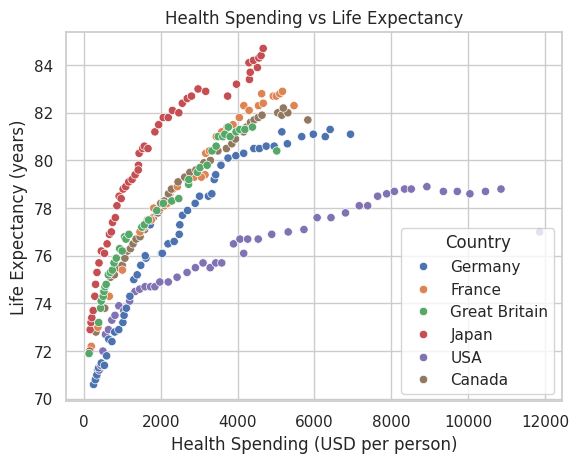

In [10]:
# TODO: Make a scatter plot of Spending_USD (x) vs Life_Expectancy (y).
# Colour the points by Country so you can see who's who.
# HINT: sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')
sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')

plt.title('Health Spending vs Life Expectancy')
plt.xlabel('Health Spending (USD per person)')
plt.ylabel('Life Expectancy (years)')
plt.show()




In [11]:
correlation = df['Spending_USD'].corr(df['Life_Expectancy'])

print("Correlation:", correlation)

Correlation: 0.5794304588530952


**✍️ Q1:** In general, as spending goes up, does life expectancy go up, down, or stay flat? Would you call the relationship strong or weak?
*Your answer:* **In general, as health spending goes up, life expectancy also increases. However, the overall correlation coefficient is roughly 0.58, which represents a moderate positive relationship rather than an extremely strong one. This is largely because the USA acts as a significant outlier, spending far more than other nations without achieving a proportionally higher life expectancy.**

## Task 2 — Find the Odd One Out *(≈15 min)*
*Every good analyst looks for what breaks the pattern.*

           Country  Spending_USD  Life_Expectancy
273            USA     11859.179             77.0
269        Germany      6938.983             81.1
268         Canada      5828.324             81.7
270         France      5468.418             82.3
271  Great Britain      5018.700             80.4
272          Japan      4665.641             84.7


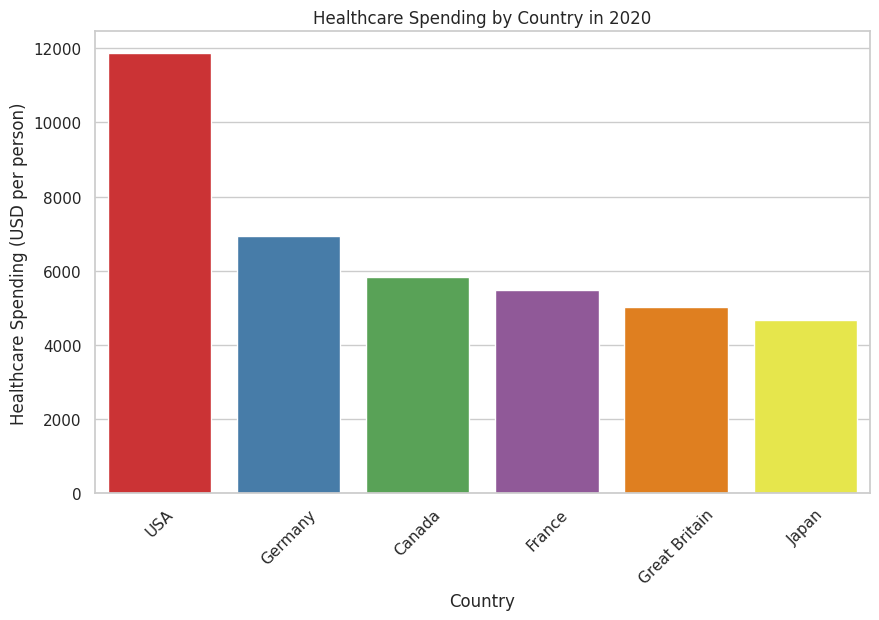

In [12]:
## — Find the Odd One Out (≈15 min)

# Choose a year
year = 2020

# Get data for that year
df_year = df[df['Year'] == year].copy()

# Sort by Spending_USD from highest to lowest
df_year = df_year.sort_values('Spending_USD', ascending=False)

# Show the data
print(df_year[['Country', 'Spending_USD', 'Life_Expectancy']])

# Bar chart of healthcare spending
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_year,
    x='Country',
    y='Spending_USD',
    hue='Country',
    palette='Set1',
    legend=False
)

plt.title(f'Healthcare Spending by Country in {year}')
plt.xlabel('Country')
plt.ylabel('Healthcare Spending (USD per person)')
plt.xticks(rotation=45)

plt.show()

**✍️ Q2:** Which country **spends the most** per person? Which country **lives the longest**? Are they the same country? *(This is the heart of the assignment — what surprised you?)*
*Your answer:* **The USA spends the most per person ($11,859 in 2020), while Japan has the highest life expectancy (84.7 years). They are not the same country. It is highly surprising that the USA spends more than double what Japan spends, yet its citizens live on average 7.7 years less.**

## Task 3 — Change Over Time *(≈15 min)*
*Has the story always been this way, or did it change?*

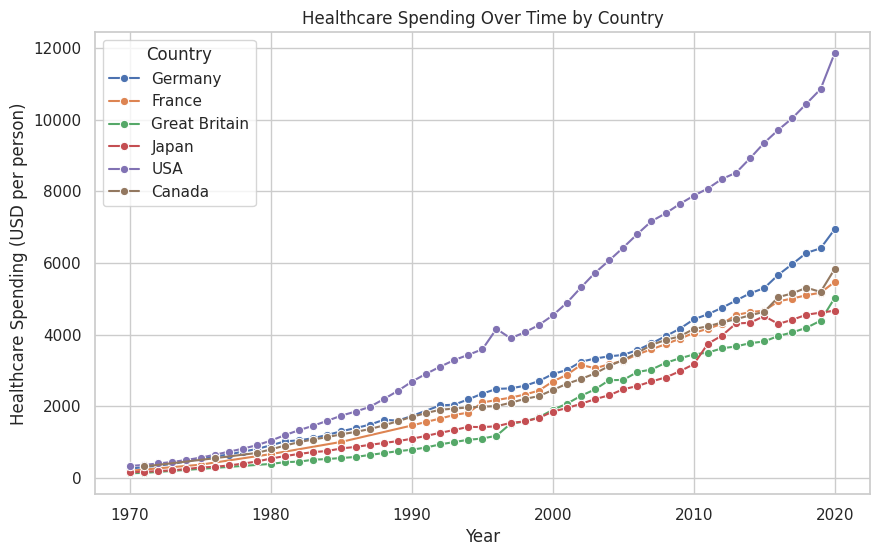

In [13]:
# TODO: Plot how ONE thing changed from 1970 to 2020, for every country.
# Pick either Spending_USD OR Life_Expectancy over Year, with one line per country.
# HINT: sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')


plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x='Year',
    y='Spending_USD',
    hue='Country',
    marker='o'
)

plt.title('Healthcare Spending Over Time by Country')
plt.xlabel('Year')
plt.ylabel('Healthcare Spending (USD per person)')
plt.legend(title='Country')
plt.show()


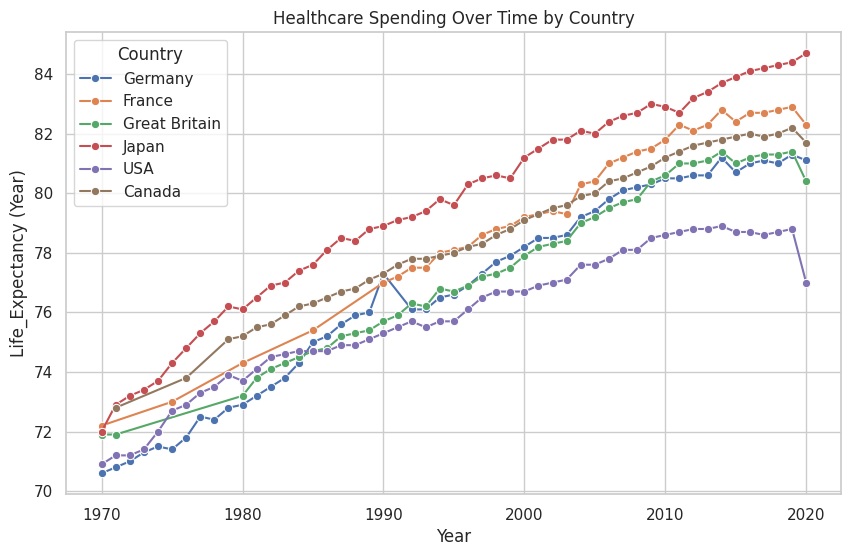

In [14]:
# TODO: Plot how ONE thing changed from 1970 to 2020, for every country.
# Pick either Spending_USD OR Life_Expectancy over Year, with one line per country.
# HINT: sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')


plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x='Year',
    y='Life_Expectancy',
    hue='Country',
    marker='o'
)

plt.title('Healthcare Spending Over Time by Country')
plt.xlabel('Year')
plt.ylabel('Life_Expectancy (Year)')
plt.legend(title='Country')
plt.show()


**✍️ Q3:** Describe one clear trend you see over time. Does one country pull away from the others at some point?
*Your answer:* **Starting around the mid-1980s, the USA began to dramatically pull away from the other five countries in terms of healthcare spending. However, this massive increase in spending did not translate to higher longevity; instead, USA life expectancy started lagging behind all other countries and has recently flattened.**

## Task 4 — Your Own Investigation *(≈10 min)*  🔍 *open-ended*
Ask **your own** question about this data and answer it with **one** chart. Ideas (or invent your own):
- Who improved their life expectancy the *most* since 1970?
- Which country gets the most "life expectancy per dollar" (best value)?
- Is any country's life expectancy *flattening* even as spending climbs?

In [15]:
# TODO: Your question, your chart. Write your question as a comment first, then the code.
# My question: ...

# Question:
# Which country improved its life expectancy the most from 1970 to 2020?

# Get life expectancy in 1970
df_1970 = df[df['Year'] == 1970][['Country', 'Life_Expectancy']]

# Get life expectancy in 2020
df_2020 = df[df['Year'] == 2020][['Country', 'Life_Expectancy']]

# Merge both years
comparison = df_1970.merge(
    df_2020,
    on='Country',
    suffixes=('_1970', '_2020')
)

# Calculate improvement
comparison['Improvement'] = (
    comparison['Life_Expectancy_2020']
    - comparison['Life_Expectancy_1970']
)

# Sort from highest improvement to lowest
comparison = comparison.sort_values(
    'Improvement',
    ascending=False
)

# Show result
print(comparison)



         Country  Life_Expectancy_1970  Life_Expectancy_2020  Improvement
3          Japan                  72.0                  84.7         12.7
0        Germany                  70.6                  81.1         10.5
1         France                  72.2                  82.3         10.1
2  Great Britain                  71.9                  80.4          8.5
4            USA                  70.9                  77.0          6.1


/tmp/ipykernel_1317/4172116826.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


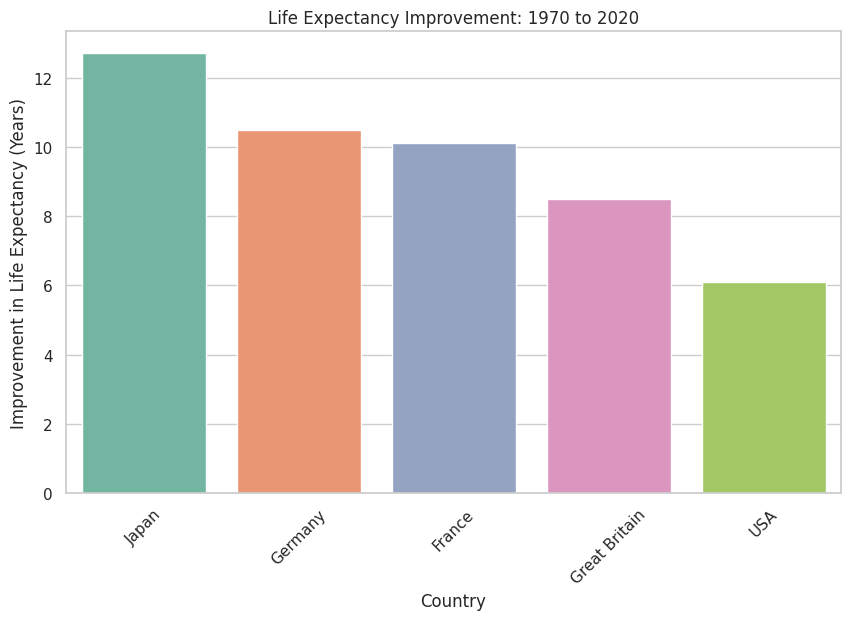

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x='Country',
    y='Improvement',
    palette='Set2'
)

plt.title('Life Expectancy Improvement: 1970 to 2020')
plt.xlabel('Country')
plt.ylabel('Improvement in Life Expectancy (Years)')
plt.xticks(rotation=45)

plt.show()

**✍️ Q4:** What did *your* chart show? State your finding in one sentence.
*Your answer:* **My chart showed that Japan improved its life expectancy the most between 1970 and 2020 (improving by 12.7 years), while the USA improved the least (improving by only 6.1 years).**

## 🏁 Your Verdict
Answer the assignment's big question in **2–3 sentences**, using what your charts showed. Then look back: **was your gut guess from the top right or wrong?**

**✍️ Final verdict:**

> **While there is an overall positive trend linking healthcare spending and life expectancy, spending more does not guarantee a longer life. The USA is a major outlier, spending significantly more than any other nation while having the lowest life expectancy of the group.**
>
> *My original guess was **right** because Japan has the longest life expectancy despite spending much less than the USA, which spends the most but has the lowest life expectancy.*